# Лабораторная работа 1

## Подготовка данных

В данных 1030 наблюдений и 8 количественных признаков. Предсказываем прочность бетона на сжатие в МПа.

| Признак | Значение | Единицы |
|---|---|---|
| Cement | Цемент | кг/м³ |
| Blast Furnace Slag | Доменный шлак | кг/м³ |
| Fly Ash | Зола | кг/м³ |
| Water | Вода | кг/м³ |
| Superplasticizer | Суперпластификатор | кг/м³ |
| Coarse Aggregate | Крупный заполнитель | кг/м³ |
| Fine Aggregate | Мелкий заполнитель | кг/м³ |
| Age | Возраст бетона | дни |

Удаляем полные дубликаты. Пропусков нет. Делим данные на train и test в отношении 80/20 с `SEED = 42`. Стандартизацию и PCA обучаем только на train. Во всех моделях сохраняем свободный член, а в Ridge не штрафуем его.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

raw_data = pd.read_csv("Concrete_Data.csv")
X = raw_data.iloc[:, :-1].copy()
y = raw_data.iloc[:, -1:].copy()

pd.DataFrame({
    "dtype": raw_data.dtypes,
    "missing": raw_data.isna().sum(),
    "min": raw_data.min(),
    "max": raw_data.max(),
})

,dtype,missing,min,max
Cement,float64,0,102.00,540.0
Blast Furnace Slag,float64,0,0.00,359.4
Fly Ash,float64,0,0.00,200.1
Water,float64,0,121.80,247.0
Superplasticizer,float64,0,0.00,32.2
Coarse Aggregate,float64,0,801.00,1145.0
Fine Aggregate,float64,0,594.00,992.6
Age,int64,0,1.00,365.0
Concrete compressive strength,float64,0,2.33,82.6


In [2]:
data = pd.concat([X, y], axis=1)
duplicate_count = int(data.duplicated().sum())
data = data.drop_duplicates().copy()

X = data.loc[:, X.columns].copy()
y = data.loc[:, y.columns].copy()

assert not data.isna().any().any()
assert len(data) >= 300 and X.shape[1] >= 5

pd.Series({
    "rows_before": len(raw_data),
    "removed_duplicates": duplicate_count,
    "rows_after": len(data),
    "remaining_duplicates": int(data.duplicated().sum()),
    "missing_values": int(data.isna().sum().sum()),
}, name="data_check")

rows_before             1030
removed_duplicates        25
rows_after              1005
remaining_duplicates       0
missing_values             0
Name: data_check, dtype: int64

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, shuffle=True
)

train_data = data.loc[X_train.index]
test_data = data.loc[X_test.index]
overlap = pd.MultiIndex.from_frame(test_data).isin(pd.MultiIndex.from_frame(train_data))
feature_overlap = pd.MultiIndex.from_frame(X_test).isin(pd.MultiIndex.from_frame(X_train))

pd.Series({
    "seed": SEED,
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "features": X_train.shape[1],
    "train_duplicates": int(train_data.duplicated().sum()),
    "test_duplicates": int(test_data.duplicated().sum()),
    "full_row_overlap": int(overlap.sum()),
    "feature_overlap": int(feature_overlap.sum()),
}, name="split_check")

seed                 42
train_rows          804
test_rows           201
features              8
train_duplicates      0
test_duplicates       0
full_row_overlap      0
feature_overlap       5
Name: split_check, dtype: int64

In [4]:
scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame({
    "train_mean": X_train_scaled.mean(),
    "train_std": X_train_scaled.std(ddof=0),
})

,train_mean,train_std
Cement,-3.402475e-16,1.0
Blast Furnace Slag,-1.546579e-17,1.0
Fly Ash,1.988459e-17,1.0
Water,-8.727126e-17,1.0
Superplasticizer,4.197858e-17,1.0
Coarse Aggregate,-4.462986e-16,1.0
Fine Aggregate,-2.916407e-16,1.0
Age,-4.639738e-17,1.0


In [5]:
pd.concat([X_train, y_train], axis=1).head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
79,531.3,0.0,0.0,141.8,28.2,852.1,893.7,3,41.30
29,475.0,0.0,0.0,228.0,0.0,932.0,594.0,7,38.60
304,277.1,0.0,97.4,160.6,11.8,973.9,875.6,3,23.14
531,436.0,0.0,0.0,218.0,0.0,838.4,719.7,28,23.85
676,166.8,250.2,0.0,203.5,0.0,975.6,692.6,7,15.75


## 1. Исследование матрицы

Сравним признаки до и после стандартизации на train: ранг, сингулярные числа и обусловленность. Все расчёты выполняем в `float64`.

Численный ранг считаем по сингулярным числам с допуском $\tau = \mathrm{eps}\cdot\max(n,p)\cdot\sigma_{max}$. Столбец единиц здесь не добавляем.

In [6]:
def matrix_diagnostics(frame):
    matrix = frame.to_numpy(dtype=np.float64)
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    tolerance = np.finfo(matrix.dtype).eps * max(matrix.shape) * singular_values[0]
    kappa_x = np.linalg.cond(matrix, p=2)
    kappa_gram = np.linalg.cond(matrix.T @ matrix, p=2)
    report = {
        "rank": int(np.count_nonzero(singular_values > tolerance)),
        "rank_tolerance": tolerance,
        "kappa_2_X": kappa_x,
        "kappa_2_XTX": kappa_gram,
        "kappa_2_X_squared": kappa_x ** 2,
    }
    return report, singular_values

raw_report, raw_singular_values = matrix_diagnostics(X_train)
scaled_report, scaled_singular_values = matrix_diagnostics(X_train_scaled)
matrix_report = pd.DataFrame({
    "Original train": raw_report,
    "Standardized train": scaled_report,
}).T

matrix_report.style.format({
    "rank": "{:.0f}",
    "rank_tolerance": "{:.8e}",
    "kappa_2_X": "{:.8g}",
    "kappa_2_XTX": "{:.8g}",
    "kappa_2_X_squared": "{:.8g}",
})

,rank,rank_tolerance,kappa_2_X,kappa_2_XTX,kappa_2_X_squared
Original train,8,6.53982715e-09,349.92663,122448.64,122448.64
Standardized train,8,7.78526139e-12,8.7848294,77.173227,77.173227


На графике делим сингулярные числа каждой матрицы на её максимальное значение. Так удобнее сравнить спад спектра.

In [7]:
singular_values_table = pd.DataFrame({
    "Original train": raw_singular_values,
    "Standardized train": scaled_singular_values,
}, index=[f"sigma_{i + 1}" for i in range(X_train.shape[1])])

singular_values_table.style.format("{:.8g}")

,Original train,Standardized train
sigma_1,36632.79,43.60908
sigma_2,3221.085,33.724676
sigma_3,2659.7045,32.198619
sigma_4,2327.8845,28.465831
sigma_5,1748.6921,27.521431
sigma_6,1388.2307,24.865082
sigma_7,693.10325,12.062155
sigma_8,104.68706,4.9641351


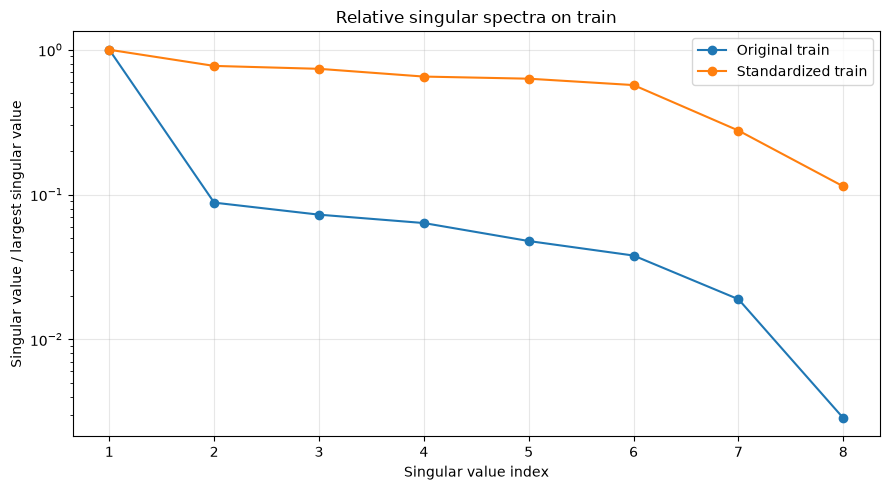

In [8]:
singular_indices = np.arange(1, X_train.shape[1] + 1)

plt.figure(figsize=(9, 5))
plt.semilogy(singular_indices, raw_singular_values / raw_singular_values[0], marker="o", label="Original train")
plt.semilogy(singular_indices, scaled_singular_values / scaled_singular_values[0], marker="o", label="Standardized train")
plt.xticks(singular_indices)
plt.xlabel("Singular value index")
plt.ylabel("Singular value / largest singular value")
plt.title("Relative singular spectra on train")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Построим корреляции признаков на train до и после стандартизации. Отдельно покажем пять самых сильных связей по модулю.

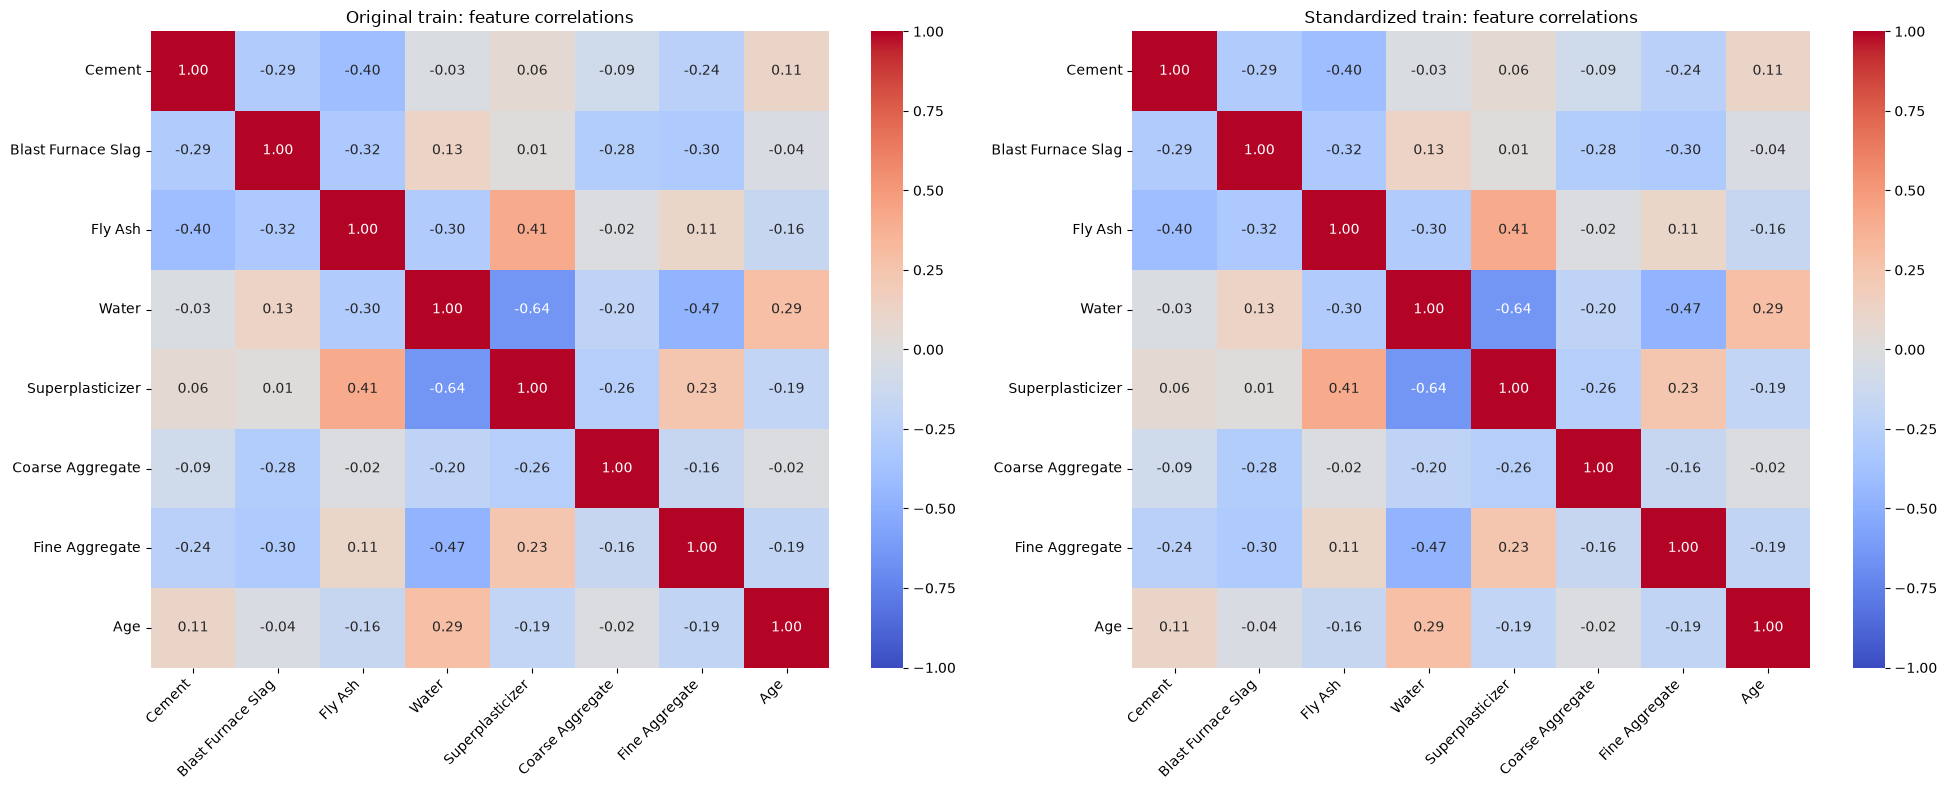

max_correlation_difference    7.771561e-16
dtype: float64

In [9]:
corr_train_raw = X_train.corr(method="pearson")
corr_train_scaled = X_train_scaled.corr(method="pearson")
max_corr_difference = np.abs(corr_train_raw - corr_train_scaled).to_numpy().max()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, correlation, title in zip(
    axes,
    [corr_train_raw, corr_train_scaled],
    ["Original train: feature correlations", "Standardized train: feature correlations"],
):
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

pd.Series({"max_correlation_difference": max_corr_difference})

In [10]:
upper_triangle = np.triu(np.ones(corr_train_raw.shape, dtype=bool), k=1)
correlation_pairs = corr_train_raw.where(upper_triangle).stack().rename("correlation")
correlation_pairs = correlation_pairs.loc[correlation_pairs.abs().sort_values(ascending=False).index]
strongest_correlations = correlation_pairs.head(5).rename_axis(["feature_1", "feature_2"]).reset_index()

strongest_correlations

,feature_1,feature_2,correlation
0,Water,Superplasticizer,-0.644291
1,Water,Fine Aggregate,-0.472193
2,Fly Ash,Superplasticizer,0.413600
3,Cement,Fly Ash,-0.399472
4,Blast Furnace Slag,Fly Ash,-0.318520


Обе матрицы имеют ранг 8 из 8. После стандартизации число обусловленности матрицы признаков уменьшается с **349.93 до 8.78**, а матрицы нормальных уравнений с **122448.64 до 77.17**.

Самая сильная парная связь у Water и Superplasticizer: **r = -0.644**. Стандартизация улучшает обусловленность, но сохраняет корреляции. Точной линейной зависимости нет, сильной мультиколлинеарности по этим результатам не видно.

## 2. Прямое решение

Добавим к стандартизированным признакам столбец единиц для свободного члена. Полученную матрицу обозначим $Z$. Решаем нормальные уравнения $A\theta=b$, где $A=Z^\top Z$ и $b=Z^\top y$.

Сравним коэффициенты, относительные остатки системы и исходной задачи МНК, а также RMSE на train и test. Один и тот же split используем во всех экспериментах.

In [11]:
Z_train = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled.to_numpy(dtype=np.float64)])
Z_test = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled.to_numpy(dtype=np.float64)])
target_train = y_train.to_numpy(dtype=np.float64).ravel()
target_test = y_test.to_numpy(dtype=np.float64).ravel()
normal_matrix = Z_train.T @ Z_train
normal_rhs = Z_train.T @ target_train
coefficient_names = ["Intercept"] + X_train.columns.tolist()
epsilon = np.finfo(np.float64).eps
rank_rcond = epsilon * max(Z_train.shape)
pivot_tolerance = epsilon * len(normal_matrix) * np.linalg.norm(normal_matrix, ord=np.inf)
result_dir = Path("results") / "mnk"
result_dir.mkdir(parents=True, exist_ok=True)

pd.Series({
    "train_rows": Z_train.shape[0],
    "test_rows": Z_test.shape[0],
    "design_columns": Z_train.shape[1],
    "design_rank": np.linalg.matrix_rank(Z_train),
    "condition_design": np.linalg.cond(Z_train, 2),
    "condition_normal": np.linalg.cond(normal_matrix, 2),
    "pivot_tolerance": pivot_tolerance,
}, name="normal_system")

train_rows          8.040000e+02
test_rows           2.010000e+02
design_columns      9.000000e+00
design_rank         9.000000e+00
condition_design    8.784829e+00
condition_normal    7.717323e+01
pivot_tolerance     4.911987e-12
Name: normal_system, dtype: float64

Реализуем Гаусса с частичным выбором ведущего элемента и LU с перестановками строк. Для LU сначала решаем нижнюю, затем верхнюю треугольную систему. Порог малого ведущего элемента равен $\mathrm{eps}\cdot p\cdot\|A\|_\infty$.

In [12]:
def forward_substitution(lower, rhs):
    solution = np.zeros_like(rhs, dtype=np.float64)
    for i in range(len(lower)):
        solution[i] = (rhs[i] - lower[i, :i] @ solution[:i]) / lower[i, i]
    return solution


def backward_substitution(upper, rhs):
    solution = np.zeros_like(rhs, dtype=np.float64)
    for i in range(len(upper) - 1, -1, -1):
        solution[i] = (rhs[i] - upper[i, i + 1:] @ solution[i + 1:]) / upper[i, i]
    return solution


def gaussian_elimination_pp(matrix, rhs, tolerance):
    upper = np.array(matrix, dtype=np.float64, copy=True)
    transformed_rhs = np.array(rhs, dtype=np.float64, copy=True)
    for k in range(len(upper)):
        pivot = k + np.argmax(np.abs(upper[k:, k]))
        if abs(upper[pivot, k]) <= tolerance:
            raise np.linalg.LinAlgError("Numerically zero pivot in Gaussian elimination")
        if pivot != k:
            upper[[k, pivot]] = upper[[pivot, k]]
            transformed_rhs[[k, pivot]] = transformed_rhs[[pivot, k]]
        for i in range(k + 1, len(upper)):
            multiplier = upper[i, k] / upper[k, k]
            upper[i, k + 1:] -= multiplier * upper[k, k + 1:]
            upper[i, k] = 0.0
            transformed_rhs[i] -= multiplier * transformed_rhs[k]
    return backward_substitution(upper, transformed_rhs)


def lu_factor_pp(matrix, tolerance):
    upper = np.array(matrix, dtype=np.float64, copy=True)
    lower = np.eye(len(upper))
    permutation = np.arange(len(upper))
    for k in range(len(upper)):
        pivot = k + np.argmax(np.abs(upper[k:, k]))
        if abs(upper[pivot, k]) <= tolerance:
            raise np.linalg.LinAlgError("Numerically zero pivot in LU factorization")
        if pivot != k:
            upper[[k, pivot]] = upper[[pivot, k]]
            lower[[k, pivot], :k] = lower[[pivot, k], :k]
            permutation[[k, pivot]] = permutation[[pivot, k]]
        for i in range(k + 1, len(upper)):
            lower[i, k] = upper[i, k] / upper[k, k]
            upper[i, k + 1:] -= lower[i, k] * upper[k, k + 1:]
            upper[i, k] = 0.0
    return lower, upper, permutation


theta_gauss = gaussian_elimination_pp(normal_matrix, normal_rhs, pivot_tolerance)
lu_lower, lu_upper, lu_permutation = lu_factor_pp(normal_matrix, pivot_tolerance)
theta_lu = backward_substitution(lu_upper, forward_substitution(lu_lower, normal_rhs[lu_permutation]))
lu_factor_error = np.linalg.norm(normal_matrix[lu_permutation] - lu_lower @ lu_upper) / np.linalg.norm(normal_matrix)

pd.Series({"LU_relative_reconstruction_error": lu_factor_error})

LU_relative_reconstruction_error    9.298880e-17
dtype: float64

Проверим симметрию и положительную определённость матрицы A. Если проверка проходит, найдём решение через Холецкого и оценим ошибку восстановления матрицы.

In [13]:
def cholesky_factor(matrix):
    lower = np.zeros_like(matrix, dtype=np.float64)
    for i in range(len(matrix)):
        for j in range(i + 1):
            value = matrix[i, j] - lower[i, :j] @ lower[j, :j]
            if i == j:
                if value <= 0:
                    raise np.linalg.LinAlgError("Nonpositive diagonal in Cholesky factorization")
                lower[i, j] = np.sqrt(value)
            else:
                lower[i, j] = value / lower[j, j]
    return lower


normal_eigenvalues = np.linalg.eigvalsh(normal_matrix)
symmetry_error = np.linalg.norm(normal_matrix - normal_matrix.T) / np.linalg.norm(normal_matrix)
spd_tolerance = epsilon * len(normal_matrix) * np.max(np.abs(normal_eigenvalues))
is_symmetric = np.allclose(normal_matrix, normal_matrix.T, rtol=0, atol=spd_tolerance)
cholesky_applicable = is_symmetric and normal_eigenvalues[0] > spd_tolerance
theta_cholesky = None
cholesky_factor_error = np.nan
cholesky_status = "not numerically SPD"

if cholesky_applicable:
    try:
        cholesky_lower = cholesky_factor(normal_matrix)
        theta_cholesky = backward_substitution(cholesky_lower.T, forward_substitution(cholesky_lower, normal_rhs))
        cholesky_factor_error = np.linalg.norm(normal_matrix - cholesky_lower @ cholesky_lower.T) / np.linalg.norm(normal_matrix)
        cholesky_status = "solved"
    except np.linalg.LinAlgError as error:
        cholesky_status = str(error)

cholesky_report = pd.Series({
    "symmetry_relative_error": symmetry_error,
    "lambda_min": normal_eigenvalues[0],
    "lambda_max": normal_eigenvalues[-1],
    "SPD_tolerance": spd_tolerance,
    "condition_number": np.linalg.cond(normal_matrix, 2),
    "factorization_relative_error": cholesky_factor_error,
    "status": cholesky_status,
})
cholesky_report

symmetry_relative_error                 0.0
lambda_min                        24.642637
lambda_max                      1901.751857
SPD_tolerance                           0.0
condition_number                  77.173227
factorization_relative_error            0.0
status                               solved
dtype: object

Для проверки используем `numpy.linalg.lstsq` на матрице Z и `numpy.linalg.solve` на нормальных уравнениях. У `lstsq` задаём тот же допуск численного ранга.

In [14]:
theta_reference, reference_residuals, reference_rank, reference_singular_values = np.linalg.lstsq(
    Z_train, target_train, rcond=rank_rcond
)
theta_library_normal = np.linalg.solve(normal_matrix, normal_rhs)


def relative_residual(matrix, solution, rhs):
    denominator = np.linalg.norm(rhs)
    numerator = np.linalg.norm(matrix @ solution - rhs)
    return numerator / denominator if denominator > 0 else numerator


def solver_metrics(name, solution, status="solved", iterations=None):
    train_prediction = Z_train @ solution
    test_prediction = Z_test @ solution
    return {
        "method": name,
        "status": status,
        "iterations": iterations,
        "normal_relative_residual": relative_residual(normal_matrix, solution, normal_rhs),
        "train_LS_relative_residual": relative_residual(Z_train, solution, target_train),
        "test_LS_relative_residual": relative_residual(Z_test, solution, target_test),
        "train_RMSE": np.sqrt(np.mean((train_prediction - target_train) ** 2)),
        "test_RMSE": np.sqrt(np.mean((test_prediction - target_test) ** 2)),
        "coefficient_relative_difference": np.linalg.norm(solution - theta_reference) / np.linalg.norm(theta_reference),
        "test_prediction_relative_difference": np.linalg.norm(test_prediction - Z_test @ theta_reference) / np.linalg.norm(Z_test @ theta_reference),
    }


solutions = {
    "NumPy lstsq": theta_reference,
    "Gauss partial pivoting": theta_gauss,
    "LU partial pivoting": theta_lu,
    "NumPy solve normal": theta_library_normal,
}
if theta_cholesky is not None:
    solutions["Cholesky"] = theta_cholesky

direct_comparison = pd.DataFrame([solver_metrics(name, solution) for name, solution in solutions.items()]).set_index("method")
direct_coefficients = pd.DataFrame(solutions, index=coefficient_names)
display(direct_coefficients)
direct_comparison.drop(columns=["iterations"]).style.format({
    column: "{:.6e}" for column in direct_comparison.select_dtypes(include="number").columns if column != "iterations"
})

,NumPy lstsq,Gauss partial pivoting,LU partial pivoting,NumPy solve normal,Cholesky
Intercept,35.066978,35.066978,35.066978,35.066978,35.066978
Cement,12.118761,12.118761,12.118761,12.118761,12.118761
Blast Furnace Slag,8.437272,8.437272,8.437272,8.437272,8.437272
Fly Ash,5.439505,5.439505,5.439505,5.439505,5.439505
Water,-2.827854,-2.827854,-2.827854,-2.827854,-2.827854
Superplasticizer,1.970793,1.970793,1.970793,1.970793,1.970793
Coarse Aggregate,1.198983,1.198983,1.198983,1.198983,1.198983
Fine Aggregate,1.669945,1.669945,1.669945,1.669945,1.669945
Age,6.894504,6.894504,6.894504,6.894504,6.894504


,status,normal_relative_residual,train_LS_relative_residual,test_LS_relative_residual,train_RMSE,test_RMSE,coefficient_relative_difference,test_prediction_relative_difference
method,,,,,,,,
NumPy lstsq,solved,6.236442e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,0.000000e+00,0.000000e+00
Gauss partial pivoting,solved,4.852195e-17,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.236393e-15,6.650325e-16
LU partial pivoting,solved,1.074347e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.581263e-15,6.666249e-16
NumPy solve normal,solved,1.052749e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.385168e-15,6.714880e-16
Cholesky,solved,1.288236e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,2.041666e-15,6.274717e-16


Матрица A симметрична и положительно определена, поэтому Холецкий применим. Гаусс, LU и Холецкий совпадают с библиотечным решением с точностью округления.

RMSE составляет **10.0018 МПа на train** и **11.1913 МПа на test**. Маленький остаток нормальных уравнений подтверждает точность решения системы, но не означает маленькую ошибку прогноза.

## 3. Итерационное решение

Реализуем Якоби и Зейделя для той же системы. До запуска построим итерационные матрицы и найдём их спектральные радиусы. Если радиус меньше 1, ожидаем сходимость.

Начинаем с нулевого вектора. Допуск относительного остатка равен **1e-10**, предел составляет **10000 итераций**. Если остаток превышает **1e8**, фиксируем расходимость. Сохраняем историю, включая начальный шаг.

In [15]:
diagonal_values = np.diag(normal_matrix)
diagonal_matrix = np.diag(diagonal_values)
strict_lower = np.tril(normal_matrix, k=-1)
strict_upper = np.triu(normal_matrix, k=1)
lower_with_diagonal = diagonal_matrix + strict_lower

jacobi_matrix = -(strict_lower + strict_upper) / diagonal_values[:, None]
jacobi_constant = normal_rhs / diagonal_values
seidel_matrix = -forward_substitution(lower_with_diagonal, strict_upper)
seidel_constant = forward_substitution(lower_with_diagonal, normal_rhs)
iteration_matrices = {"Jacobi": jacobi_matrix, "Gauss-Seidel": seidel_matrix}
spectral_radii = {
    name: float(np.max(np.abs(np.linalg.eigvals(matrix))))
    for name, matrix in iteration_matrices.items()
}
iteration_forecast = pd.DataFrame([
    {
        "method": name,
        "spectral_radius": radius,
        "expected_convergence": radius < 1,
    }
    for name, radius in spectral_radii.items()
]).set_index("method")

theta_initial = np.zeros(Z_train.shape[1])
iteration_tolerance = 1e-10
iteration_limit = 10000
divergence_limit = 1e8

display(iteration_forecast)
display(pd.DataFrame(jacobi_matrix, index=coefficient_names, columns=coefficient_names).style.format("{:.4f}"))
display(pd.DataFrame(seidel_matrix, index=coefficient_names, columns=coefficient_names).style.format("{:.4f}"))

,spectral_radius,expected_convergence
method,,
Jacobi,1.365363,False
Gauss-Seidel,0.939832,True


,Intercept,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
Intercept,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000
Cement,0.0000,-0.0000,0.2897,0.3995,0.0268,-0.0568,0.0940,0.2409,-0.1134
Blast Furnace Slag,-0.0000,0.2897,-0.0000,0.3185,-0.1259,-0.0138,0.2789,0.2976,0.0376
Fly Ash,-0.0000,0.3995,0.3185,-0.0000,0.2967,-0.4136,0.0185,-0.1087,0.1633
Water,0.0000,0.0268,-0.1259,0.2967,-0.0000,0.6443,0.2036,0.4722,-0.2877
Superplasticizer,-0.0000,-0.0568,-0.0138,-0.4136,0.6443,-0.0000,0.2626,-0.2345,0.1853
Coarse Aggregate,0.0000,0.0940,0.2789,0.0185,0.2036,0.2626,-0.0000,0.1632,0.0228
Fine Aggregate,0.0000,0.2409,0.2976,-0.1087,0.4722,-0.2345,0.1632,-0.0000,0.1885
Age,0.0000,-0.1134,0.0376,0.1633,-0.2877,0.1853,0.0228,0.1885,-0.0000


,Intercept,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
Intercept,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000
Cement,-0.0000,0.0000,0.2897,0.3995,0.0268,-0.0568,0.0940,0.2409,-0.1134
Blast Furnace Slag,-0.0000,0.0000,0.0839,0.4342,-0.1181,-0.0302,0.3062,0.3674,0.0048
Fly Ash,-0.0000,0.0000,0.1425,0.2979,0.2698,-0.4459,0.1536,0.1045,0.1195
Water,-0.0000,0.0000,0.0395,0.0444,0.0956,0.5143,0.2132,0.4634,-0.2559
Superplasticizer,-0.0000,0.0000,-0.0511,-0.1232,-0.0499,0.5194,0.3269,0.0022,-0.0226
Coarse Aggregate,-0.0000,0.0000,0.0479,0.1409,-0.0190,0.2191,0.2263,0.3852,-0.0424
Fine Aggregate,-0.0000,0.0000,0.1177,0.2659,-0.0043,0.1826,0.1580,0.4372,0.0272
Age,-0.0000,0.0000,-0.0040,0.0374,-0.0014,-0.0798,0.0601,-0.0381,0.1061


In [16]:
def stationary_solve(matrix, rhs, method, initial, tolerance, max_iterations, divergence_threshold):
    solution = np.array(initial, dtype=np.float64, copy=True)
    diagonal = np.diag(matrix)
    lower = np.tril(matrix)
    upper = np.triu(matrix, k=1)
    off_diagonal = matrix - np.diag(diagonal)
    residual = relative_residual(matrix, solution, rhs)
    history = [{"iteration": 0, "normal_relative_residual": residual}]
    status = "converged" if residual <= tolerance else "iteration_limit"
    if residual <= tolerance:
        return solution, pd.DataFrame(history), status

    for iteration in range(1, max_iterations + 1):
        if method == "Jacobi":
            solution = (rhs - off_diagonal @ solution) / diagonal
        elif method == "Gauss-Seidel":
            solution = forward_substitution(lower, rhs - upper @ solution)
        else:
            raise ValueError("Unknown stationary method")
        residual = relative_residual(matrix, solution, rhs)
        history.append({"iteration": iteration, "normal_relative_residual": residual})
        if not np.isfinite(residual) or not np.all(np.isfinite(solution)):
            status = "nonfinite"
            break
        if residual <= tolerance:
            status = "converged"
            break
        if residual > divergence_threshold:
            status = "diverged"
            break
    return solution, pd.DataFrame(history), status


iteration_results = {}
history_parts = []
for method in iteration_matrices:
    solution, history, status = stationary_solve(
        normal_matrix, normal_rhs, method, theta_initial,
        iteration_tolerance, iteration_limit, divergence_limit
    )
    iteration_results[method] = {
        "solution": solution,
        "status": status,
        "iterations": int(history.iloc[-1]["iteration"]),
    }
    history_parts.append(history.assign(method=method))

iteration_history = pd.concat(history_parts, ignore_index=True)
iteration_comparison = pd.DataFrame([
    solver_metrics(method, result["solution"], result["status"], result["iterations"])
    for method, result in iteration_results.items()
]).set_index("method")
iteration_comparison.insert(0, "spectral_radius", pd.Series(spectral_radii))
iteration_comparison

,spectral_radius,status,iterations,normal_relative_residual,train_LS_relative_residual,test_LS_relative_residual,train_RMSE,test_RMSE,coefficient_relative_difference,test_prediction_relative_difference
method,,,,,,,,,,
Jacobi,1.365363,diverged,82,1.253887e+08,7.892639e+07,7.045480e+07,3.042618e+09,2.812172e+09,5.039655e+07,7.517956e+07
Gauss-Seidel,0.939832,converged,294,9.974260e-11,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,2.451964e-09,4.333549e-10


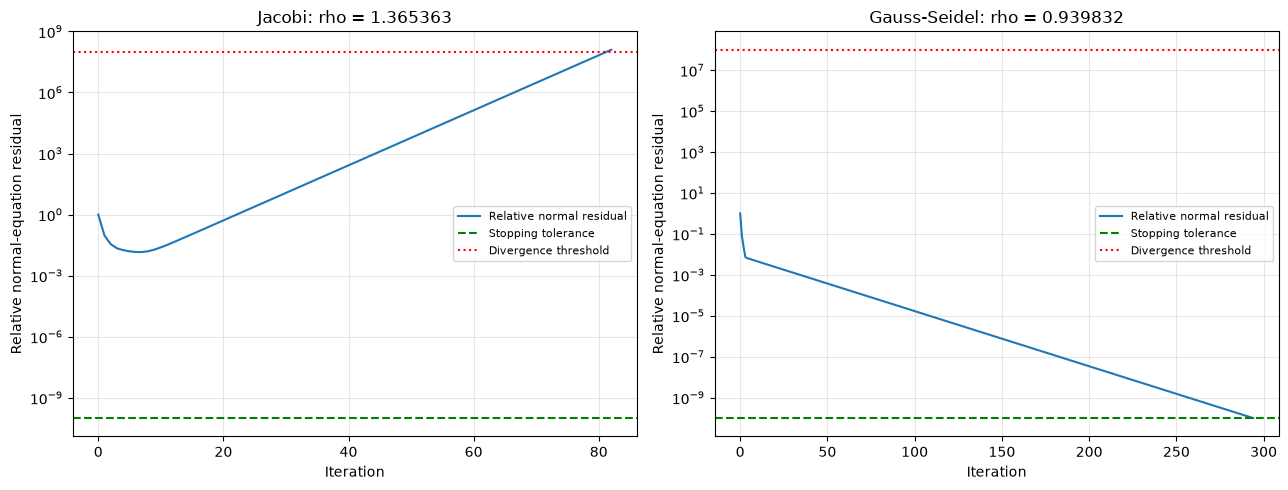

,iteration,normal_relative_residual,method
78,78,3.607995e+07,Jacobi
79,79,4.926223e+07,Jacobi
80,80,6.726083e+07,Jacobi
81,81,9.183545e+07,Jacobi
82,82,1.253887e+08,Jacobi
373,290,1.278439e-10,Gauss-Seidel
374,291,1.201519e-10,Gauss-Seidel
375,292,1.129225e-10,Gauss-Seidel
376,293,1.061282e-10,Gauss-Seidel
377,294,9.974260e-11,Gauss-Seidel


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, iteration_matrices):
    history = iteration_history.loc[iteration_history["method"] == method]
    ax.semilogy(history["iteration"], history["normal_relative_residual"], label="Relative normal residual")
    ax.axhline(iteration_tolerance, color="green", linestyle="--", label="Stopping tolerance")
    ax.axhline(divergence_limit, color="red", linestyle=":", label="Divergence threshold")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Relative normal-equation residual")
    ax.set_title(f"{method}: rho = {spectral_radii[method]:.6f}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(result_dir / "iteration_convergence.png", dpi=160, bbox_inches="tight")
plt.show()

iteration_history.groupby("method", sort=False).tail(5)

Спектральный прогноз подтвердился: у Якоби радиус **1.3654**, метод расходится. У Зейделя радиус **0.9398**, метод сходится за **294 итерации**.

История остатков и статусы сохранены в таблицах. Последний вектор Якоби служит для диагностики и не считается решением МНК.

## 4. Решение через SVD

Построим SVD матрицы Z и найдём псевдообратное решение. Оставляем сингулярные числа выше $\mathrm{eps}\cdot\max(n,p)\cdot\sigma_{max}$. Явную псевдообратную матрицу не строим.

In [18]:
svd_u, svd_values, svd_vt = np.linalg.svd(Z_train, full_matrices=False)
svd_tolerance = rank_rcond * svd_values[0]
svd_keep = svd_values > svd_tolerance
svd_rank = int(svd_keep.sum())
theta_svd = svd_vt[svd_keep].T @ ((svd_u[:, svd_keep].T @ target_train) / svd_values[svd_keep])
svd_reconstruction_error = np.linalg.norm(Z_train - (svd_u * svd_values) @ svd_vt) / np.linalg.norm(Z_train)
solutions["SVD"] = theta_svd
for method, result in iteration_results.items():
    solutions[method] = result["solution"]

display(pd.Series({
    "rank": svd_rank,
    "columns": Z_train.shape[1],
    "rank_tolerance": svd_tolerance,
    "relative_reconstruction_error": svd_reconstruction_error,
}, name="SVD_check"))
pd.DataFrame({"singular_value": svd_values, "retained": svd_keep}, index=[f"sigma_{i + 1}" for i in range(len(svd_values))])

rank                             9.000000e+00
columns                          9.000000e+00
rank_tolerance                   7.785261e-12
relative_reconstruction_error    8.504628e-16
Name: SVD_check, dtype: float64

,singular_value,retained
sigma_1,43.609080,True
sigma_2,33.724676,True
sigma_3,32.198619,True
sigma_4,28.465831,True
sigma_5,28.354894,True
sigma_6,27.521431,True
sigma_7,24.865082,True
sigma_8,12.062155,True
sigma_9,4.964135,True


Сравним методы по коэффициентам, остаткам и RMSE. Коэффициенты покажем в стандартизированном масштабе и в исходных единицах. Для Якоби сохраним статус расходимости.

In [19]:
comparison_rows = []
for method, solution in solutions.items():
    result = iteration_results.get(method, {})
    comparison_rows.append(solver_metrics(method, solution, result.get("status", "solved"), result.get("iterations")))
solver_comparison = pd.DataFrame(comparison_rows).set_index("method")
coefficients_standardized = pd.DataFrame(solutions, index=coefficient_names)
coefficients_original = coefficients_standardized.copy()
coefficients_original.iloc[1:] = coefficients_standardized.iloc[1:].to_numpy() / scaler.scale_[:, None]
coefficients_original.iloc[0] = coefficients_standardized.iloc[0].to_numpy() - scaler.mean_ @ coefficients_original.iloc[1:].to_numpy()

display(coefficients_standardized)
display(coefficients_original)
solver_comparison.style.format({
    "iterations": "{:.0f}",
    **{column: "{:.6e}" for column in solver_comparison.select_dtypes(include="number").columns if column != "iterations"},
}, na_rep="-")

,NumPy lstsq,Gauss partial pivoting,LU partial pivoting,NumPy solve normal,Cholesky,SVD,Jacobi,Gauss-Seidel
Intercept,35.066978,35.066978,35.066978,35.066978,35.066978,35.066978,3.506698e+01,35.066978
Cement,12.118761,12.118761,12.118761,12.118761,12.118761,12.118761,2.901799e+08,12.118761
Blast Furnace Slag,8.437272,8.437272,8.437272,8.437272,8.437272,8.437272,3.731200e+08,8.437272
Fly Ash,5.439505,5.439505,5.439505,5.439505,5.439505,5.439505,-8.239611e+08,5.439505
Water,-2.827854,-2.827854,-2.827854,-2.827854,-2.827854,-2.827854,1.055079e+09,-2.827854
Superplasticizer,1.970793,1.970793,1.970793,1.970793,1.970793,1.970793,-9.542286e+08,1.970793
Coarse Aggregate,1.198983,1.198983,1.198983,1.198983,1.198983,1.198983,2.829195e+07,1.198983
Fine Aggregate,1.669945,1.669945,1.669945,1.669945,1.669945,1.669945,-8.097429e+08,1.669945
Age,6.894504,6.894504,6.894504,6.894504,6.894504,6.894504,5.755193e+08,6.894504


,NumPy lstsq,Gauss partial pivoting,LU partial pivoting,NumPy solve normal,Cholesky,SVD,Jacobi,Gauss-Seidel
Intercept,-23.389347,-23.389347,-23.389347,-23.389347,-23.389347,-23.389347,-1.349928e+09,-23.389346
Cement,0.116667,0.116667,0.116667,0.116667,0.116667,0.116667,2.793546e+06,0.116667
Blast Furnace Slag,0.098066,0.098066,0.098066,0.098066,0.098066,0.098066,4.336772e+06,0.098066
Fly Ash,0.084585,0.084585,0.084585,0.084585,0.084585,0.084585,-1.281265e+07,0.084585
Water,-0.131391,-0.131391,-0.131391,-0.131391,-0.131391,-0.131391,4.902229e+07,-0.131391
Superplasticizer,0.331480,0.331480,0.331480,0.331480,0.331480,0.331480,-1.604976e+08,0.331480
Coarse Aggregate,0.015522,0.015522,0.015522,0.015522,0.015522,0.015522,3.662679e+05,0.015522
Fine Aggregate,0.020649,0.020649,0.020649,0.020649,0.020649,0.020649,-1.001268e+07,0.020649
Age,0.110642,0.110642,0.110642,0.110642,0.110642,0.110642,9.235870e+06,0.110642


,status,iterations,normal_relative_residual,train_LS_relative_residual,test_LS_relative_residual,train_RMSE,test_RMSE,coefficient_relative_difference,test_prediction_relative_difference
method,,,,,,,,,
NumPy lstsq,solved,-,6.236442e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,0.000000e+00,0.000000e+00
Gauss partial pivoting,solved,-,4.852195e-17,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.236393e-15,6.650325e-16
LU partial pivoting,solved,-,1.074347e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.581263e-15,6.666249e-16
NumPy solve normal,solved,-,1.052749e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,1.385168e-15,6.714880e-16
Cholesky,solved,-,1.288236e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,2.041666e-15,6.274717e-16
SVD,solved,-,3.925885e-16,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,4.239306e-16,4.764414e-16
Jacobi,diverged,82,1.253887e+08,7.892639e+07,7.045480e+07,3.042618e+09,2.812172e+09,5.039655e+07,7.517956e+07
Gauss-Seidel,converged,294,9.974260e-11,2.594495e-01,2.803819e-01,1.000179e+01,1.119132e+01,2.451964e-09,4.333549e-10


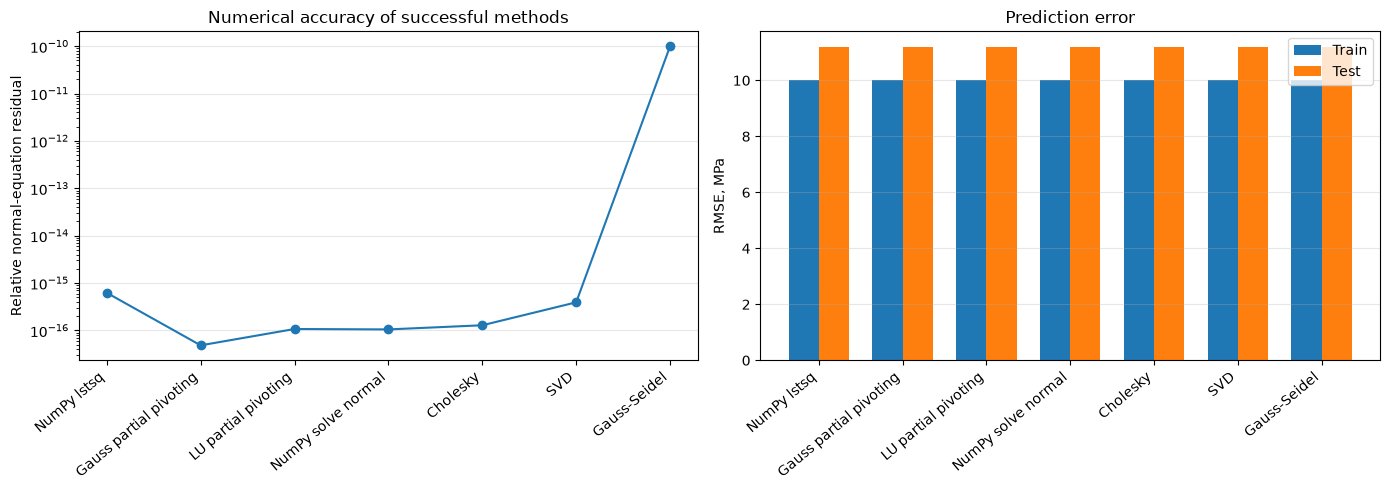

In [20]:
successful_methods = solver_comparison.index[solver_comparison["status"].isin(["solved", "converged"])]
comparison_plot = solver_comparison.loc[successful_methods]
positions = np.arange(len(comparison_plot))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].semilogy(positions, comparison_plot["normal_relative_residual"], marker="o")
axes[0].set_ylabel("Relative normal-equation residual")
axes[0].set_title("Numerical accuracy of successful methods")
axes[1].bar(positions - 0.18, comparison_plot["train_RMSE"], width=0.36, label="Train")
axes[1].bar(positions + 0.18, comparison_plot["test_RMSE"], width=0.36, label="Test")
axes[1].set_ylabel("RMSE, MPa")
axes[1].set_title("Prediction error")
axes[1].legend()
for ax in axes:
    ax.set_xticks(positions, comparison_plot.index, rotation=40, ha="right")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(result_dir / "solver_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

solver_comparison.to_csv(result_dir / "solver_comparison.csv", float_format="%.17g")
iteration_history.to_csv(result_dir / "iteration_history.csv", index=False, float_format="%.17g")
coefficients_standardized.to_csv(result_dir / "coefficients_standardized.csv", float_format="%.17g")
coefficients_original.to_csv(result_dir / "coefficients_original.csv", float_format="%.17g")

Ранг Z со свободным членом равен **9 из 9**. Гаусс, LU, Холецкий и SVD дают одинаковые прогнозы с точностью округления. Зейдель достигает того же решения с заданным допуском.

Для этой системы удобно использовать Холецкого. SVD также даёт решение и позволяет контролировать потерю ранга.

## 5. Ухудшение обусловленности

Добавим признак $x_{new}=x_j+cx_k+\varepsilon z$ для $\varepsilon=10^{-2},10^{-6},0$. Пару признаков выбираем по самой сильной корреляции на train, коэффициент c равен знаку этой корреляции.

Шум создаём один раз с фиксированным seed и приводим к единичной дисперсии на train. Удаляем его проекцию на исходные признаки, чтобы получить новое направление. На test применяем параметры, найденные на train.

Для каждого ε сравним прямые методы и SVD. Сохраним ранг, обусловленность, норму коэффициентов, остатки, RMSE и статус. Ошибки методов обрабатываем, чтобы notebook выполнялся дальше.

In [21]:
feature_train = X_train_scaled.to_numpy(dtype=np.float64)
feature_test = X_test_scaled.to_numpy(dtype=np.float64)
correlation_upper = X_train_scaled.corr().where(np.triu(np.ones((feature_train.shape[1], feature_train.shape[1]), dtype=bool), 1))
feature_pair = correlation_upper.abs().stack().idxmax()
feature_j = X_train_scaled.columns.get_loc(feature_pair[0])
feature_k = X_train_scaled.columns.get_loc(feature_pair[1])
mixing_coefficient = float(np.sign(correlation_upper.loc[feature_pair[0], feature_pair[1]]))

noise_rng = np.random.default_rng(SEED + 145)
noise_raw_train = noise_rng.standard_normal(len(feature_train))
noise_raw_test = noise_rng.standard_normal(len(feature_test))
noise_projection = np.linalg.lstsq(Z_train, noise_raw_train, rcond=rank_rcond)[0]
noise_train_residual = noise_raw_train - Z_train @ noise_projection
noise_scale = noise_train_residual.std(ddof=0)
noise_train = noise_train_residual / noise_scale
noise_test = (noise_raw_test - Z_test @ noise_projection) / noise_scale
stress_epsilons = [1e-2, 1e-6, 0.0]

pd.Series({
    "feature_j": feature_pair[0],
    "feature_k": feature_pair[1],
    "correlation": correlation_upper.loc[feature_pair[0], feature_pair[1]],
    "c": mixing_coefficient,
    "noise_seed": SEED + 145,
    "noise_mean": noise_train.mean(),
    "noise_variance": noise_train.var(ddof=0),
    "noise_projection_norm": np.linalg.norm(Z_train.T @ noise_train),
}, name="conditioning_setup")

feature_j                           Water
feature_k                Superplasticizer
correlation                     -0.644291
c                                    -1.0
noise_seed                            187
noise_mean                            0.0
noise_variance                        1.0
noise_projection_norm                 0.0
Name: conditioning_setup, dtype: object

In [22]:
def design_report(design):
    values = np.linalg.svd(design, compute_uv=False)
    tolerance = np.finfo(np.float64).eps * max(design.shape) * values[0]
    rank = int(np.count_nonzero(values > tolerance))
    gram = design.T @ design
    return {
        "rank": rank,
        "columns": design.shape[1],
        "rank_tolerance": tolerance,
        "sigma_min": values[-1],
        "condition_design": values[0] / values[-1] if rank == design.shape[1] else np.inf,
        "condition_design_float64": values[0] / values[-1],
        "condition_gram": np.linalg.cond(gram, 2) if rank == design.shape[1] else np.inf,
        "condition_gram_float64": np.linalg.cond(gram, 2),
        "gram_lambda_min": np.linalg.eigvalsh(gram)[0],
    }


def svd_least_squares(design, target):
    u, values, vt = np.linalg.svd(design, full_matrices=False)
    tolerance = np.finfo(np.float64).eps * max(design.shape) * values[0]
    keep = values > tolerance
    return vt[keep].T @ ((u[:, keep].T @ target) / values[keep])


def direct_normal_solution(matrix, rhs, method):
    tolerance = np.finfo(np.float64).eps * len(matrix) * np.linalg.norm(matrix, np.inf)
    if method == "Gauss partial pivoting":
        return gaussian_elimination_pp(matrix, rhs, tolerance)
    if method == "LU partial pivoting":
        lower, upper, permutation = lu_factor_pp(matrix, tolerance)
        return backward_substitution(upper, forward_substitution(lower, rhs[permutation]))
    if method == "Cholesky":
        lower = cholesky_factor(matrix)
        return backward_substitution(lower.T, forward_substitution(lower, rhs))
    raise ValueError("Unknown direct method")


stress_rows = []
stress_diagnostics = []
stress_solutions = {}
stress_designs = {}
for perturbation in stress_epsilons:
    new_train = feature_train[:, feature_j] + mixing_coefficient * feature_train[:, feature_k] + perturbation * noise_train
    new_test = feature_test[:, feature_j] + mixing_coefficient * feature_test[:, feature_k] + perturbation * noise_test
    design_train = np.column_stack([Z_train, new_train])
    design_test = np.column_stack([Z_test, new_test])
    gram = design_train.T @ design_train
    rhs = design_train.T @ target_train
    diagnostic = design_report(design_train)
    stress_diagnostics.append({"epsilon": perturbation, **diagnostic})
    stress_designs[perturbation] = (design_train, design_test)
    stress_reference = svd_least_squares(design_train, target_train)

    for method in ["Gauss partial pivoting", "LU partial pivoting", "Cholesky", "SVD"]:
        row = {"epsilon": perturbation, "method": method, "rank": diagnostic["rank"], "condition_design": diagnostic["condition_design"]}
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                solution = stress_reference.copy() if method == "SVD" else direct_normal_solution(gram, rhs, method)
                if not np.all(np.isfinite(solution)):
                    raise FloatingPointError("Nonfinite coefficients")
                train_prediction = design_train @ solution
                test_prediction = design_test @ solution
                row.update({
                    "success": True,
                    "unique_by_rank": diagnostic["rank"] == design_train.shape[1],
                    "status": "rank_deficient_returned" if method != "SVD" and diagnostic["rank"] < design_train.shape[1] else "solved",
                    "stop_reason": "SVD rank truncation" if method == "SVD" and diagnostic["rank"] < design_train.shape[1] else "completed on a rank-deficient rounded system" if diagnostic["rank"] < design_train.shape[1] else "completed",
                    "coefficient_norm": np.linalg.norm(solution),
                    "weights_norm": np.linalg.norm(solution[1:]),
                    "normal_relative_residual": relative_residual(gram, solution, rhs),
                    "train_LS_relative_residual": relative_residual(design_train, solution, target_train),
                    "test_LS_relative_residual": relative_residual(design_test, solution, target_test),
                    "train_RMSE": np.sqrt(np.mean((train_prediction - target_train) ** 2)),
                    "test_RMSE": np.sqrt(np.mean((test_prediction - target_test) ** 2)),
                    "coefficient_relative_difference_SVD": np.linalg.norm(solution - stress_reference) / np.linalg.norm(stress_reference),
                })
                stress_solutions[(perturbation, method)] = solution
        except (np.linalg.LinAlgError, FloatingPointError, ValueError) as error:
            row.update({"success": False, "unique_by_rank": diagnostic["rank"] == design_train.shape[1], "status": "failed", "stop_reason": f"{type(error).__name__}: {error}"})
        stress_rows.append(row)

conditioning_diagnostics = pd.DataFrame(stress_diagnostics)
conditioning_comparison = pd.DataFrame(stress_rows)
display(conditioning_diagnostics)
display(conditioning_comparison)
conditioning_diagnostics.to_csv(result_dir / "conditioning_diagnostics.csv", index=False, float_format="%.17g")
conditioning_comparison.to_csv(result_dir / "conditioning_comparison.csv", index=False, float_format="%.17g")

,epsilon,rank,columns,rank_tolerance,sigma_min,condition_design,condition_design_float64,condition_gram,condition_gram_float64,gram_lambda_min
0,0.010000,10,10,1.176121e-11,1.637025e-01,4.024394e+02,4.024394e+02,1.619575e+05,1.619575e+05,2.679850e-02
1,0.000001,10,10,1.176114e-11,1.637071e-05,4.024259e+06,4.024259e+06,1.619073e+13,1.619073e+13,2.683773e-10
2,0.000000,9,10,1.176114e-11,1.523321e-14,inf,4.324759e+15,inf,1.391398e+17,1.307625e-13


,epsilon,method,rank,condition_design,success,unique_by_rank,status,stop_reason,coefficient_norm,weights_norm,normal_relative_residual,train_LS_relative_residual,test_LS_relative_residual,train_RMSE,test_RMSE,coefficient_relative_difference_SVD
0,0.010000,Gauss partial pivoting,10,4.024394e+02,True,True,solved,completed,54.286757,41.441032,3.737497e-16,0.259379,0.280709,9.999079,11.204366,3.204711e-12
1,0.010000,LU partial pivoting,10,4.024394e+02,True,True,solved,completed,54.286757,41.441032,5.043910e-16,0.259379,0.280709,9.999079,11.204366,2.746847e-12
2,0.010000,Cholesky,10,4.024394e+02,True,True,solved,completed,54.286757,41.441032,3.599621e-16,0.259379,0.280709,9.999079,11.204366,5.784335e-13
3,0.010000,SVD,10,4.024394e+02,True,True,solved,completed,54.286757,41.441032,6.080932e-16,0.259379,0.280709,9.999079,11.204366,0.000000e+00
4,0.000001,Gauss partial pivoting,10,4.024259e+06,True,True,solved,completed,403661.891248,403661.889725,8.683205e-12,0.259379,0.280709,9.999079,11.204364,9.775863e-05
5,0.000001,LU partial pivoting,10,4.024259e+06,True,True,solved,completed,403661.892005,403661.890481,5.203337e-12,0.259379,0.280709,9.999079,11.204364,9.775675e-05
6,0.000001,Cholesky,10,4.024259e+06,True,True,solved,completed,403704.699504,403704.697981,2.047660e-12,0.259379,0.280709,9.999079,11.204366,8.280789e-06
7,0.000001,SVD,10,4.024259e+06,True,True,solved,completed,403701.356538,403701.355015,1.260418e-11,0.259379,0.280709,9.999079,11.204366,0.000000e+00
8,0.000000,Gauss partial pivoting,9,inf,False,False,failed,LinAlgError: Numerically zero pivot in Gaussia...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.000000,LU partial pivoting,9,inf,False,False,failed,LinAlgError: Numerically zero pivot in LU fact...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


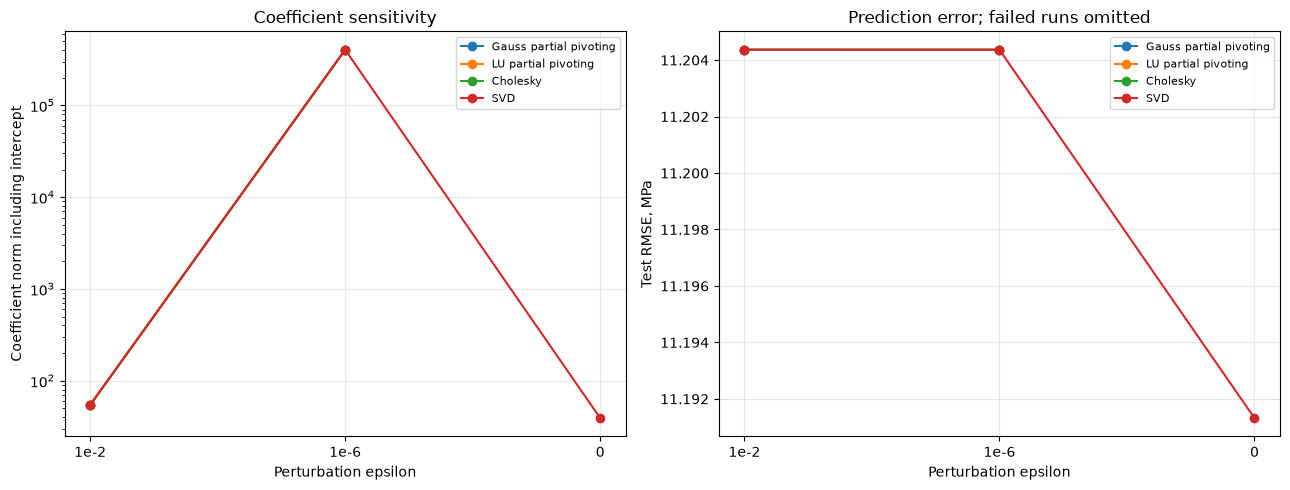

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for method in conditioning_comparison["method"].unique():
    rows = conditioning_comparison.loc[conditioning_comparison["method"] == method].set_index("epsilon").reindex(stress_epsilons)
    axes[0].semilogy(range(3), rows["coefficient_norm"], marker="o", label=method)
    axes[1].plot(range(3), rows["test_RMSE"], marker="o", label=method)
for ax in axes:
    ax.set_xticks(range(3), ["1e-2", "1e-6", "0"])
    ax.set_xlabel("Perturbation epsilon")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Coefficient norm including intercept")
axes[0].set_title("Coefficient sensitivity")
axes[1].set_ylabel("Test RMSE, MPa")
axes[1].set_title("Prediction error; failed runs omitted")
plt.tight_layout()
fig.savefig(result_dir / "conditioning_experiment.png", dpi=160, bbox_inches="tight")
plt.show()

Выбраны Water и Superplasticizer, **c = -1**. При ε = 1e-2 число обусловленности около **402**, при ε = 1e-6 около **4.02e6**. Коэффициенты становятся большими и чувствительными к округлению.

При ε = 0 ранг падает с **10 до 9**. Прямые методы фиксируют отказ или результат на вырожденной округлённой системе. SVD отбрасывает нулевое направление и возвращает решение минимальной нормы. Небольшой остаток системы при плохой обусловленности ещё не гарантирует устойчивых коэффициентов.

## 6. Сокращение размерности

Сначала посмотрим, сколько главных компонент нужно для 95% дисперсии. PCA обучаем на стандартизированном train методом полного SVD.

In [24]:
pca = PCA(n_components=0.95, svd_solver="full")
train_components = pca.fit_transform(X_train_scaled)
test_components = pca.transform(X_test_scaled)

component_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
X_train_pca = pd.DataFrame(train_components, index=X_train.index, columns=component_names)
X_test_pca = pd.DataFrame(test_components, index=X_test.index, columns=component_names)

pca_variance = pd.DataFrame({
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance_ratio": pca.explained_variance_ratio_.cumsum(),
}, index=component_names)

display(pd.Series({
    "components": pca.n_components_,
    "explained_variance_ratio": pca.explained_variance_ratio_.sum(),
    "train_rows": len(X_train_pca),
    "test_rows": len(X_test_pca),
}, name="PCA_check"))
pca_variance

components                    6.000000
explained_variance_ratio      0.973548
train_rows                  804.000000
test_rows                   201.000000
Name: PCA_check, dtype: float64

,explained_variance_ratio,cumulative_variance_ratio
PC1,0.295670,0.295670
PC2,0.176827,0.472498
PC3,0.161186,0.633684
PC4,0.125980,0.759664
PC5,0.117760,0.877424
PC6,0.096124,0.973548


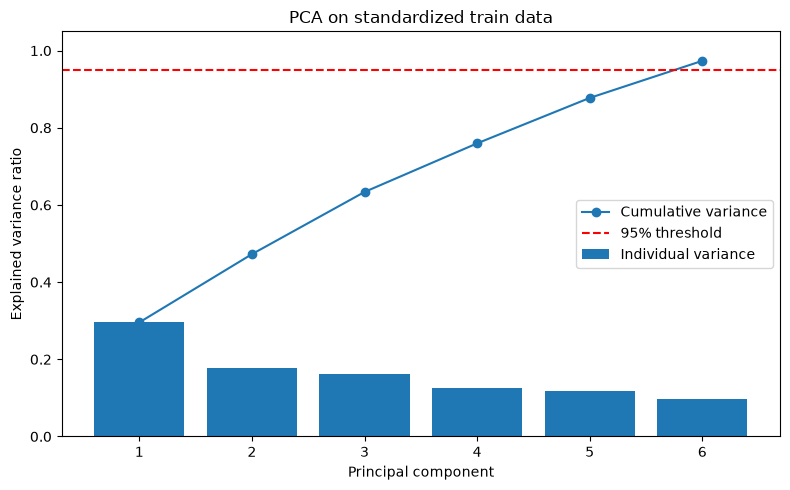

In [25]:
components = np.arange(1, pca.n_components_ + 1)

plt.figure(figsize=(8, 5))
plt.bar(components, pca.explained_variance_ratio_, label="Individual variance")
plt.plot(components, pca.explained_variance_ratio_.cumsum(), marker="o", label="Cumulative variance")
plt.axhline(0.95, color="red", linestyle="--", label="95% threshold")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA on standardized train data")
plt.legend()
plt.tight_layout()
plt.show()

Сравним PCR и truncated SVD для **k = 1, 2, 3** и полного ранга **8**. Свободный член сохраняем отдельно и в k не включаем.

Для каждого k найдём долю объяснённой дисперсии, ошибку восстановления, обусловленность и RMSE на train и test. Проверим, что оба способа дают одинаковые прогнозы, а полный ранг воспроизводит исходное МНК.

In [26]:
reduction_mean = feature_train.mean(axis=0)
centered_train = feature_train - reduction_mean
centered_test = feature_test - reduction_mean
reduction_u, reduction_values, reduction_vt = np.linalg.svd(centered_train, full_matrices=False)
reduction_tolerance = epsilon * max(centered_train.shape) * reduction_values[0]
feature_rank = int(np.count_nonzero(reduction_values > reduction_tolerance))
component_counts = sorted({1, 2, 3, feature_rank})
reduction_rows = []
reduction_predictions = {}
reduction_coefficients = {}

for count in component_counts:
    fitted_pca = PCA(n_components=count, svd_solver="full")
    pcr_train = fitted_pca.fit_transform(feature_train)
    pcr_test = fitted_pca.transform(feature_test)
    pcr_design_train = np.column_stack([np.ones(len(pcr_train)), pcr_train])
    pcr_design_test = np.column_stack([np.ones(len(pcr_test)), pcr_test])
    pcr_theta = svd_least_squares(pcr_design_train, target_train)
    pcr_weights = fitted_pca.components_.T @ pcr_theta[1:]
    pcr_intercept = pcr_theta[0] - fitted_pca.mean_ @ pcr_weights

    directions = reduction_vt[:count].T
    tsvd_train = centered_train @ directions
    tsvd_test = centered_test @ directions
    tsvd_coordinates = (reduction_u[:, :count].T @ (target_train - target_train.mean())) / reduction_values[:count]
    tsvd_weights = directions @ tsvd_coordinates
    tsvd_intercept = target_train.mean() - reduction_mean @ tsvd_weights

    variants = [
        ("PCR", pcr_train, pcr_test, pcr_design_train @ pcr_theta, pcr_design_test @ pcr_theta,
         fitted_pca.explained_variance_ratio_.sum(), fitted_pca.inverse_transform(pcr_train) - fitted_pca.mean_,
         np.r_[pcr_intercept, pcr_weights]),
        ("Truncated SVD", tsvd_train, tsvd_test, target_train.mean() + tsvd_train @ tsvd_coordinates,
         target_train.mean() + tsvd_test @ tsvd_coordinates,
         np.sum(reduction_values[:count] ** 2) / np.sum(reduction_values ** 2),
         tsvd_train @ directions.T, np.r_[tsvd_intercept, tsvd_weights]),
    ]
    for method, scores_train, scores_test, train_prediction, test_prediction, explained, reconstruction, coefficients in variants:
        reduced_design = np.column_stack([np.ones(len(scores_train)), scores_train])
        reduction_rows.append({
            "method": method, "k": count, "full_feature_rank": feature_rank,
            "explained_variance_ratio": explained,
            "relative_reconstruction_error": np.linalg.norm(centered_train - reconstruction) / np.linalg.norm(centered_train),
            "condition_reduced_features": np.linalg.cond(scores_train, 2),
            "condition_reduced_design": np.linalg.cond(reduced_design, 2),
            "condition_reduced_gram": np.linalg.cond(reduced_design.T @ reduced_design, 2),
            "coefficient_norm": np.linalg.norm(coefficients),
            "train_RMSE": np.sqrt(np.mean((train_prediction - target_train) ** 2)),
            "test_RMSE": np.sqrt(np.mean((test_prediction - target_test) ** 2)),
        })
        reduction_predictions[(method, count)] = (train_prediction, test_prediction)
        reduction_coefficients[(method, count)] = coefficients

dimensionality_comparison = pd.DataFrame(reduction_rows)
display(dimensionality_comparison)
dimensionality_comparison.to_csv(result_dir / "dimensionality_reduction.csv", index=False, float_format="%.17g")

,method,k,full_feature_rank,explained_variance_ratio,relative_reconstruction_error,condition_reduced_features,condition_reduced_design,condition_reduced_gram,coefficient_norm,train_RMSE,test_RMSE
0,PCR,1,8,0.295670,8.392435e-01,1.000000,1.537974,2.365363,35.066981,16.012937,17.295917
1,Truncated SVD,1,8,0.295670,8.392435e-01,1.000000,1.537974,2.365363,35.066981,16.012937,17.295917
2,PCR,2,8,0.472498,7.262935e-01,1.293091,1.537974,2.365363,35.068071,16.009560,17.264789
3,Truncated SVD,2,8,0.472498,7.262935e-01,1.293091,1.537974,2.365363,35.068071,16.009560,17.264789
4,PCR,3,8,0.633684,6.052403e-01,1.354377,1.537974,2.365363,36.029165,12.968949,14.812158
5,Truncated SVD,3,8,0.633684,6.052403e-01,1.354377,1.537974,2.365363,36.029165,12.968949,14.812158
6,PCR,8,8,1.000000,3.490018e-15,8.784829,8.784829,77.173227,39.255246,10.001795,11.191320
7,Truncated SVD,8,8,1.000000,8.683175e-16,8.784829,8.784829,77.173227,39.255246,10.001795,11.191320


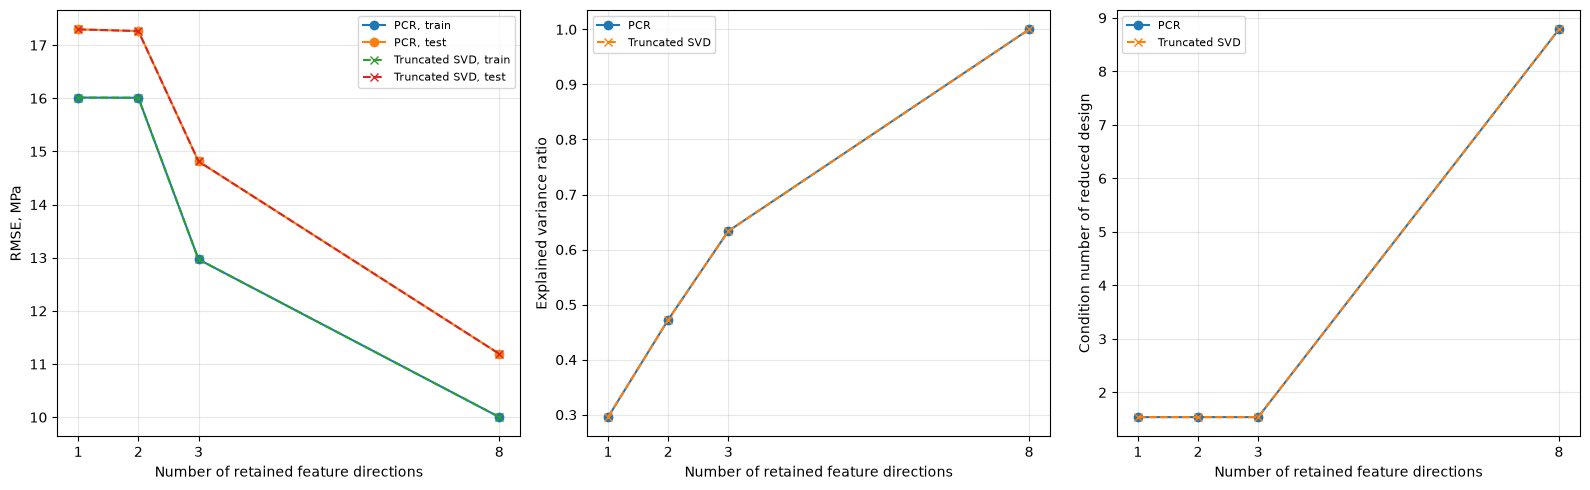

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for method, marker, line in [("PCR", "o", "-"), ("Truncated SVD", "x", "--")]:
    rows = dimensionality_comparison.loc[dimensionality_comparison["method"] == method]
    axes[0].plot(rows["k"], rows["train_RMSE"], marker=marker, linestyle=line, label=f"{method}, train")
    axes[0].plot(rows["k"], rows["test_RMSE"], marker=marker, linestyle=line, label=f"{method}, test")
    axes[1].plot(rows["k"], rows["explained_variance_ratio"], marker=marker, linestyle=line, label=method)
    axes[2].plot(rows["k"], rows["condition_reduced_design"], marker=marker, linestyle=line, label=method)
for ax in axes:
    ax.set_xticks(component_counts)
    ax.set_xlabel("Number of retained feature directions")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE, MPa")
axes[1].set_ylabel("Explained variance ratio")
axes[2].set_ylabel("Condition number of reduced design")
plt.tight_layout()
fig.savefig(result_dir / "dimensionality_reduction.png", dpi=160, bbox_inches="tight")
plt.show()

При k = 1, 2, 3, 8 тестовые RMSE равны **17.2959, 17.2648, 14.8122, 11.1913 МПа**. PCR и truncated SVD дают одинаковые прогнозы с точностью округления.

Сокращение числа компонент улучшает обусловленность, но здесь ухудшает прогноз. При полном ранге получаем исходное решение МНК. Значения k заданы заранее и не подбираются по test.

## 7. Ridge-регуляризация

Добавим штраф на веса, сохраняя свободный член без штрафа. Возьмём **7 значений λ от 1e-8 до 1e7** с равным шагом по логарифму. Сетка включает почти обычное МНК и сильное сжатие весов.

Выбираем λ по минимальной средней RMSE пятиблочной кросс-валидации внутри train. При равенстве с точностью 1e-12 берём большее λ. Одинаковые строки признаков помещаем в один блок через `GroupKFold`. Scaler в каждом блоке обучаем заново только на его обучающей части. Test при выборе λ не используем.

In [28]:
lambda_grid = np.logspace(-8, 7, 7)
ridge_penalty = np.diag(np.r_[0.0, np.ones(feature_train.shape[1])])
cv_groups = pd.factorize(pd.MultiIndex.from_frame(X_train))[0]
ridge_cv = GroupKFold(n_splits=5)
cv_rows = []
cv_membership = np.full(len(X_train), -1, dtype=int)

for fold, (fit_indices, validation_indices) in enumerate(ridge_cv.split(X_train, target_train, groups=cv_groups)):
    fold_scaler = StandardScaler()
    fold_train = fold_scaler.fit_transform(X_train.iloc[fit_indices])
    fold_validation = fold_scaler.transform(X_train.iloc[validation_indices])
    fold_design = np.column_stack([np.ones(len(fit_indices)), fold_train])
    validation_design = np.column_stack([np.ones(len(validation_indices)), fold_validation])
    fold_matrix = fold_design.T @ fold_design
    fold_rhs = fold_design.T @ target_train[fit_indices]
    cv_membership[validation_indices] = fold
    for regularization in lambda_grid:
        regularized = fold_matrix + regularization * ridge_penalty
        fold_theta = direct_normal_solution(regularized, fold_rhs, "Cholesky")
        prediction = validation_design @ fold_theta
        cv_rows.append({
            "lambda": regularization, "fold": fold,
            "validation_RMSE": np.sqrt(np.mean((prediction - target_train[validation_indices]) ** 2)),
        })

ridge_cv_details = pd.DataFrame(cv_rows)
ridge_cv_summary = ridge_cv_details.groupby("lambda")["validation_RMSE"].agg(["mean", "std"]).rename(columns={"mean": "CV_RMSE_mean", "std": "CV_RMSE_std"})
best_cv_error = ridge_cv_summary["CV_RMSE_mean"].min()
eligible_lambdas = ridge_cv_summary.index[np.isclose(ridge_cv_summary["CV_RMSE_mean"], best_cv_error, rtol=0, atol=1e-12)]
selected_lambda = float(eligible_lambdas.max())

display(ridge_cv_summary.loc[[selected_lambda]])
ridge_cv_details.to_csv(result_dir / "ridge_cv_details.csv", index=False, float_format="%.17g")
pd.DataFrame({"source_index": X_train.index, "feature_group": cv_groups, "validation_fold": cv_membership}).to_csv(result_dir / "ridge_cv_folds.csv", index=False)

,CV_RMSE_mean,CV_RMSE_std
lambda,,
0.316228,10.125938,0.138896


После выбора λ обучим модели на всём train. Для каждого λ покажем обусловленность, норму коэффициентов и RMSE на train и test.

Отдельно считаем норму весов без свободного члена и обусловленность блока весов. При большом λ веса стремятся к нулю, а свободный член остаётся близким к среднему y_train.

In [29]:
ridge_rows = []
ridge_solutions = {}
for regularization in lambda_grid:
    ridge_matrix = normal_matrix + regularization * (ridge_penalty.T @ ridge_penalty)
    ridge_theta = direct_normal_solution(ridge_matrix, normal_rhs, "Cholesky")
    ridge_solutions[regularization] = ridge_theta
    train_prediction = Z_train @ ridge_theta
    test_prediction = Z_test @ ridge_theta
    ridge_rows.append({
        "lambda": regularization,
        "selected_by_CV": regularization == selected_lambda,
        "condition_regularized_system": np.linalg.cond(ridge_matrix, 2),
        "condition_regularized_feature_block": np.linalg.cond(ridge_matrix[1:, 1:], 2),
        "coefficient_norm": np.linalg.norm(ridge_theta),
        "weights_norm": np.linalg.norm(ridge_theta[1:]),
        "intercept": ridge_theta[0],
        "regularized_relative_residual": relative_residual(ridge_matrix, ridge_theta, normal_rhs),
        "train_RMSE": np.sqrt(np.mean((train_prediction - target_train) ** 2)),
        "test_RMSE": np.sqrt(np.mean((test_prediction - target_test) ** 2)),
    })
ridge_comparison = pd.DataFrame(ridge_rows).set_index("lambda").join(ridge_cv_summary)
ridge_selected = ridge_comparison.loc[selected_lambda]
display(ridge_comparison)
display(pd.DataFrame({"OLS": theta_reference, "Ridge selected": ridge_solutions[selected_lambda]}, index=coefficient_names))
ridge_comparison.to_csv(result_dir / "ridge_comparison.csv", float_format="%.17g")
pd.DataFrame({f"lambda={value:.10g}": coefficients for value, coefficients in ridge_solutions.items()}, index=coefficient_names).to_csv(result_dir / "ridge_coefficients.csv", float_format="%.17g")

,selected_by_CV,condition_regularized_system,condition_regularized_feature_block,coefficient_norm,weights_norm,intercept,regularized_relative_residual,train_RMSE,test_RMSE,CV_RMSE_mean,CV_RMSE_std
lambda,,,,,,,,,,,
1.000000e-08,False,77.173227,77.173227,39.255246,17.643168,35.066978,1.634078e-16,10.001795,11.191320,10.126126,0.137507
3.162278e-06,False,77.173218,77.173218,39.255245,17.643167,35.066978,1.391109e-16,10.001795,11.191320,10.126126,0.137507
1.000000e-03,False,77.170136,77.170136,39.255100,17.642844,35.066978,1.628798e-16,10.001795,11.191322,10.126126,0.137511
3.162278e-01,True,76.208116,76.208116,39.209918,17.542085,35.066978,1.486883e-16,10.001829,11.191900,10.125938,0.138896
1.000000e+02,False,16.059929,16.059929,36.854723,11.339209,35.066978,4.609430e-17,10.278030,11.590230,10.441315,0.315632
3.162278e+04,False,41.697175,1.059313,35.068396,0.315418,35.066978,4.852195e-17,15.763058,17.061269,15.795118,1.076960
1.000000e+07,False,12440.176308,1.000188,35.066978,0.001027,35.066978,9.763385e-17,16.012138,17.295640,15.992565,1.090935


,OLS,Ridge selected
Intercept,35.066978,35.066978
Cement,12.118761,12.050952
Blast Furnace Slag,8.437272,8.369701
Fly Ash,5.439505,5.379860
Water,-2.827854,-2.874748
Superplasticizer,1.970793,1.970190
Coarse Aggregate,1.198983,1.152319
Fine Aggregate,1.669945,1.608500
Age,6.894504,6.887929


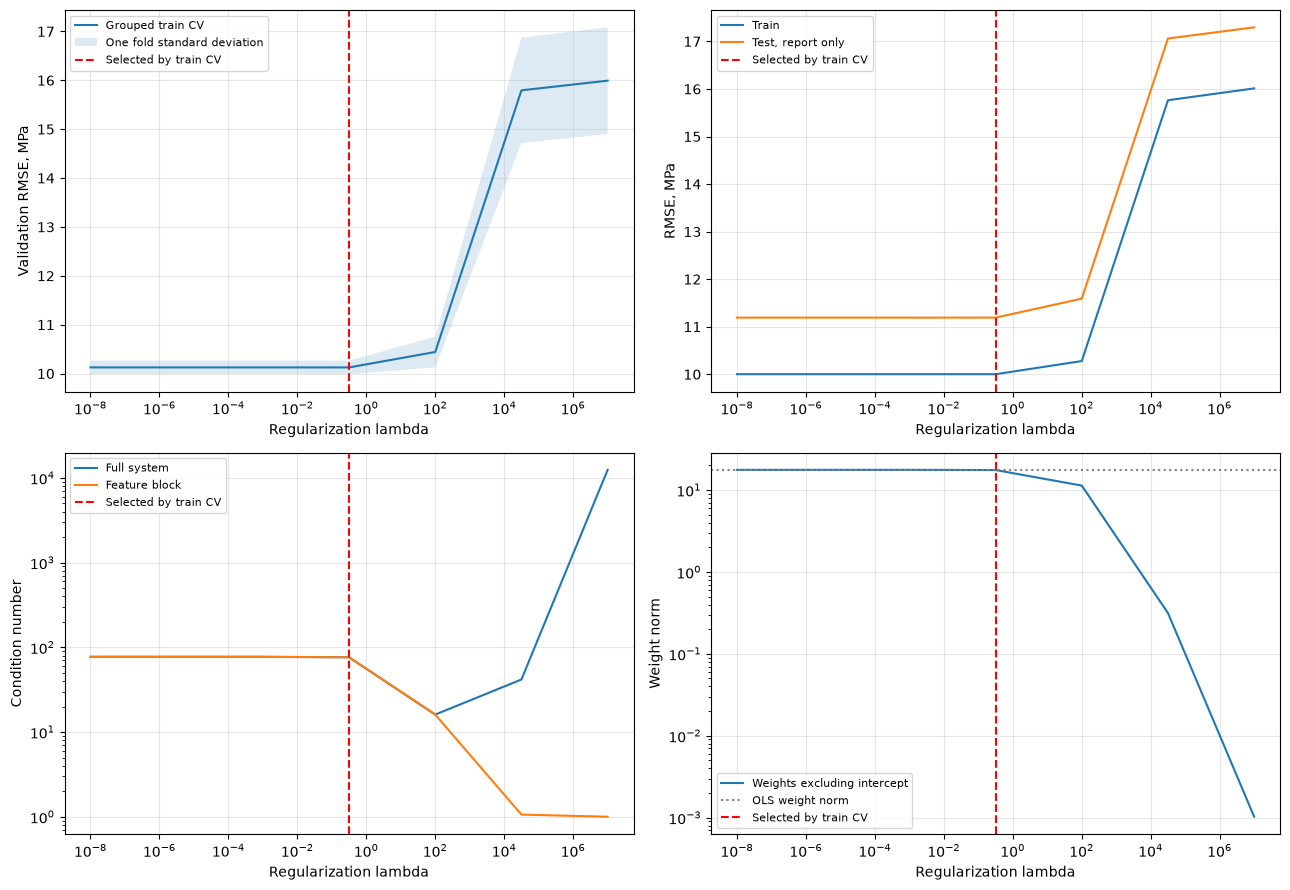

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
values = ridge_comparison.index.to_numpy()
axes[0, 0].semilogx(values, ridge_comparison["CV_RMSE_mean"], label="Grouped train CV")
axes[0, 0].fill_between(values, ridge_comparison["CV_RMSE_mean"] - ridge_comparison["CV_RMSE_std"], ridge_comparison["CV_RMSE_mean"] + ridge_comparison["CV_RMSE_std"], alpha=0.15, label="One fold standard deviation")
axes[0, 0].set_ylabel("Validation RMSE, MPa")
axes[0, 1].semilogx(values, ridge_comparison["train_RMSE"], label="Train")
axes[0, 1].semilogx(values, ridge_comparison["test_RMSE"], label="Test, report only")
axes[0, 1].set_ylabel("RMSE, MPa")
axes[1, 0].loglog(values, ridge_comparison["condition_regularized_system"], label="Full system")
axes[1, 0].loglog(values, ridge_comparison["condition_regularized_feature_block"], label="Feature block")
axes[1, 0].set_ylabel("Condition number")
axes[1, 1].loglog(values, ridge_comparison["weights_norm"], label="Weights excluding intercept")
axes[1, 1].axhline(np.linalg.norm(theta_reference[1:]), color="gray", linestyle=":", label="OLS weight norm")
axes[1, 1].set_ylabel("Weight norm")
for ax in axes.ravel():
    ax.axvline(selected_lambda, color="red", linestyle="--", label="Selected by train CV")
    ax.set_xlabel("Regularization lambda")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(result_dir / "ridge_regularization.png", dpi=160, bbox_inches="tight")
plt.show()

По минимуму RMSE на кросс-валидации выбрано **λ = 0.31622777**. Средняя CV-RMSE равна **10.1259 МПа**. Test в выборе не участвовал.

RMSE Ridge составляет **10.0018 МПа на train** и **11.1919 МПа на test**. У обычного МНК тестовая RMSE равна **11.1913 МПа**. Заметного выигрыша от регуляризации здесь нет.

При усилении штрафа веса сжимаются, а ошибка на train растёт. Обусловленность блока весов приближается к единице. У полной системы при очень большом λ она может снова расти из-за свободного члена без штрафа.

## Итоговое сравнение

Исходные методы, сокращение размерности и Ridge покажем в отдельных таблицах. Искусственно ухудшенная задача остаётся в разделе 5.

In [31]:
summary_columns = ["status", "normal_relative_residual", "train_RMSE", "test_RMSE"]
display(solver_comparison.loc[:, summary_columns])
display(dimensionality_comparison.loc[:, [
    "method", "k", "explained_variance_ratio", "condition_reduced_design", "train_RMSE", "test_RMSE"
]])
ridge_summary = pd.DataFrame({
    "OLS": {
        "lambda": 0.0,
        "condition_system": np.linalg.cond(normal_matrix, 2),
        "weights_norm": np.linalg.norm(theta_reference[1:]),
        "train_RMSE": solver_comparison.loc["NumPy lstsq", "train_RMSE"],
        "test_RMSE": solver_comparison.loc["NumPy lstsq", "test_RMSE"],
    },
    "Ridge": {
        "lambda": selected_lambda,
        "condition_system": ridge_selected["condition_regularized_system"],
        "weights_norm": ridge_selected["weights_norm"],
        "train_RMSE": ridge_selected["train_RMSE"],
        "test_RMSE": ridge_selected["test_RMSE"],
    },
}).T
display(ridge_summary)
ridge_summary.to_csv(result_dir / "final_comparison.csv", float_format="%.17g")

,status,normal_relative_residual,train_RMSE,test_RMSE
method,,,,
NumPy lstsq,solved,6.236442e-16,1.000179e+01,1.119132e+01
Gauss partial pivoting,solved,4.852195e-17,1.000179e+01,1.119132e+01
LU partial pivoting,solved,1.074347e-16,1.000179e+01,1.119132e+01
NumPy solve normal,solved,1.052749e-16,1.000179e+01,1.119132e+01
Cholesky,solved,1.288236e-16,1.000179e+01,1.119132e+01
SVD,solved,3.925885e-16,1.000179e+01,1.119132e+01
Jacobi,diverged,1.253887e+08,3.042618e+09,2.812172e+09
Gauss-Seidel,converged,9.974260e-11,1.000179e+01,1.119132e+01


,method,k,explained_variance_ratio,condition_reduced_design,train_RMSE,test_RMSE
0,PCR,1,0.295670,1.537974,16.012937,17.295917
1,Truncated SVD,1,0.295670,1.537974,16.012937,17.295917
2,PCR,2,0.472498,1.537974,16.009560,17.264789
3,Truncated SVD,2,0.472498,1.537974,16.009560,17.264789
4,PCR,3,0.633684,1.537974,12.968949,14.812158
5,Truncated SVD,3,0.633684,1.537974,12.968949,14.812158
6,PCR,8,1.000000,8.784829,10.001795,11.191320
7,Truncated SVD,8,1.000000,8.784829,10.001795,11.191320


,lambda,condition_system,weights_norm,train_RMSE,test_RMSE
OLS,0.000000,77.173227,17.643168,10.001795,11.19132
Ridge,0.316228,76.208116,17.542085,10.001829,11.19190


Стандартизация заметно улучшила обусловленность. Прямые методы, SVD и сошедшийся Зейдель дали одинаковые прогнозы. Для исходной задачи подходит Холецкий, а SVD удобен при потере ранга.

При почти зависимом признаке коэффициенты теряют устойчивость. Сокращение размерности улучшает обусловленность, но в этих данных повышает RMSE. Ridge сжимает веса, однако заметного выигрыша на test не даёт.